In [51]:
# load data
import pandas as pd

df = pd.read_csv('Biomes.csv')
df

,ID,name,dimensionID,treesOrGrass,generateStructures,minecraftVersion,precipitation
0,1,badlands,1,1,1,1.7.2,NaN
1,2,bamboo_jungle,1,1,1,1.14.0,Rain
2,3,basalt_deltas,2,0,1,1.16.0,NaN
3,4,beach,1,0,1,1.0.0,Rain
4,5,birch_forest,1,1,0,1.7.2,Rain
...,...,...,...,...,...,...,...
59,60,windswept_forest,1,1,0,1.1.0,Rain
60,61,windswept_gravelly_hills,1,0,0,1.1.0,Rain
61,62,windswept_hills,1,1,0,1.1.0,Rain
62,63,windswept_savanna,1,1,0,1.7.2,NaN


In [52]:
# EDA
print(f'Cek 5 data teratas \n {df.head()} \n')

print(f'Cek tipe data \n {df.dtypes} \n')

print(f'Cek missing values \n {df.isnull().sum()} \n')

print(f'Cek duplicate \n {df.duplicated().sum()}')

Cek 5 data teratas 
    ID           name  dimensionID  treesOrGrass  generateStructures  \
0   1       badlands            1             1                   1   
1   2  bamboo_jungle            1             1                   1   
2   3  basalt_deltas            2             0                   1   
3   4          beach            1             0                   1   
4   5   birch_forest            1             1                   0   

  minecraftVersion precipitation  
0            1.7.2           NaN  
1           1.14.0          Rain  
2           1.16.0           NaN  
3            1.0.0          Rain  
4            1.7.2          Rain   

Cek tipe data 
 ID                    int64
name                    str
dimensionID           int64
treesOrGrass          int64
generateStructures    int64
minecraftVersion        str
precipitation           str
dtype: object 

Cek missing values 
 ID                     0
name                   0
dimensionID            0
treesOrGrass    

In [53]:
# handle missing values
df.dropna(inplace = True)

C:\Users\mozar\AppData\Local\Temp\ipykernel_24248\2510173879.py:2: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.dropna(inplace = True)


                          ID  dimensionID  treesOrGrass  generateStructures
ID                  1.000000          NaN      0.166899           -0.248854
dimensionID              NaN          NaN           NaN                 NaN
treesOrGrass        0.166899          NaN      1.000000           -0.073254
generateStructures -0.248854          NaN     -0.073254            1.000000


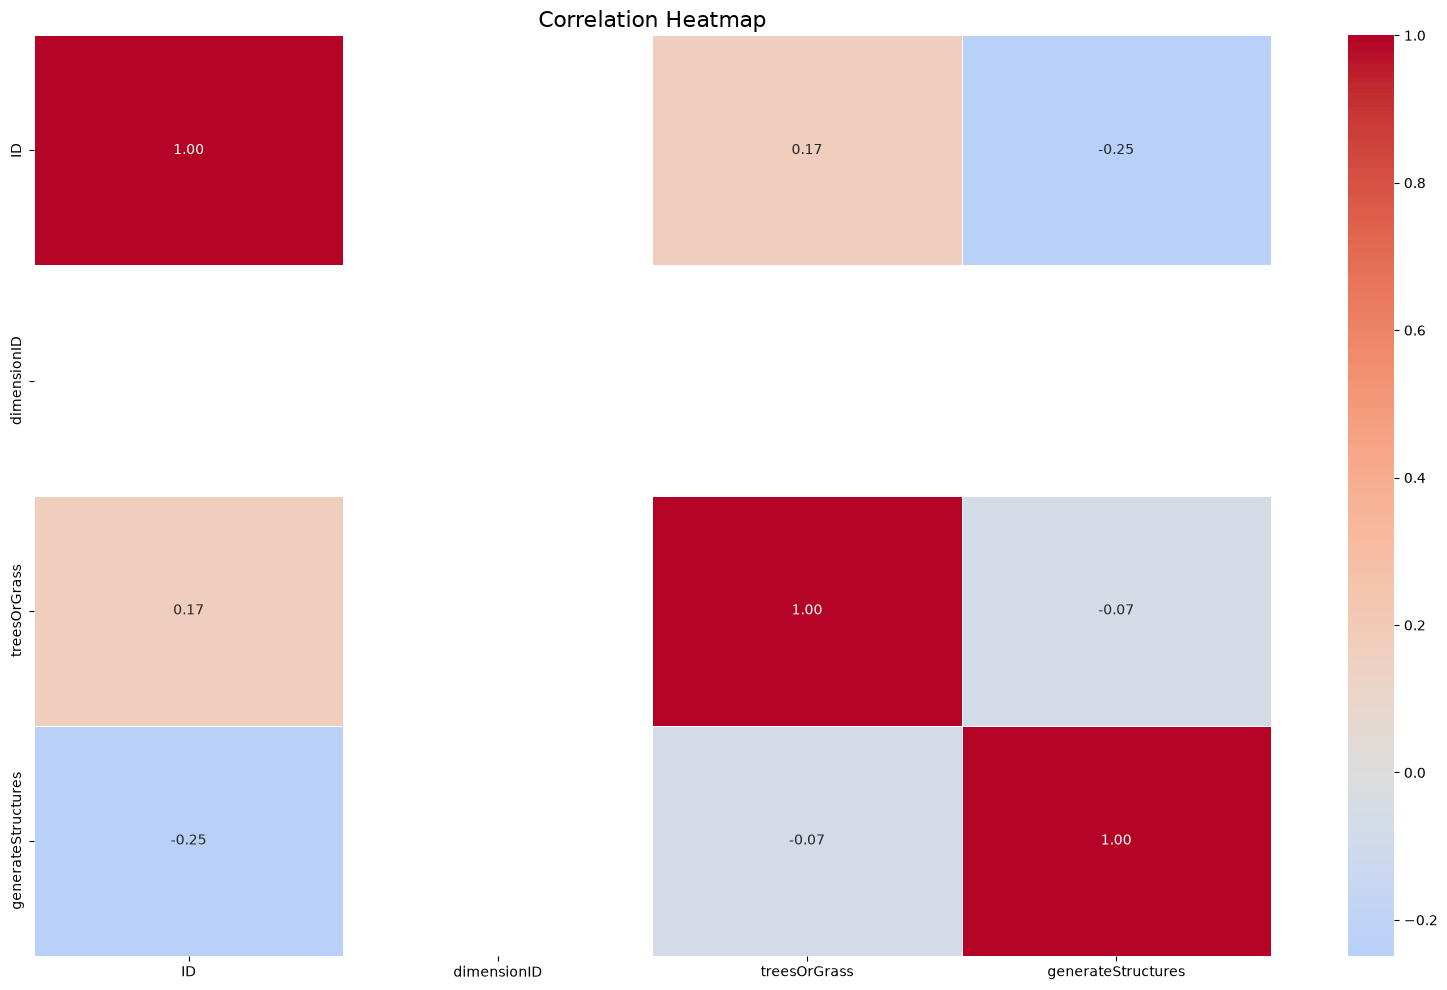

In [54]:
# Outlier
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np

correlation_matrix = df.select_dtypes(
    include=np.number
).corr()

print(correlation_matrix)

plt.figure(figsize=(16, 10))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5,
    center=0
)

plt.title('Correlation Heatmap', fontsize=16)
plt.tight_layout()
plt.show()

In [55]:
# Handle Outlier
numerical_columns = df.select_dtypes(include='number').columns

Q1 = df[numerical_columns].quantile(0.25)
Q3 = df[numerical_columns].quantile(0.75)

IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outlier_mask = (
    (df[numerical_columns] < lower_bound) |
    (df[numerical_columns] > upper_bound)
)

outlier_summary = pd.DataFrame({
    'Outlier Count': outlier_mask.sum(),
    'Percentage': outlier_mask.mean() * 100
})

outlier_summary.sort_values(
    by='Outlier Count',
    ascending=False
)

,Outlier Count,Percentage
ID,0,0.0
dimensionID,0,0.0
treesOrGrass,0,0.0
generateStructures,0,0.0


In [56]:
# creating x and y variables
X = df.drop(columns=['ID', 'name', 'treesOrGrass'])
y = df['treesOrGrass']

In [57]:
# encoding
X = pd.get_dummies(X, drop_first=True)

In [58]:
# split data
from sklearn.model_selection import train_test_split

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size = 0.2,
    random_state = 42
)

In [ ]:
# training model
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import train_test_split

model = RandomForestClassifier(random_state=42)
model.fit(x_train, y_train)


ValueError: Found input variables with inconsistent numbers of samples: [51, 36]